In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import pandas as pd
import os
import h5py
import json
from datetime import datetime
import time
import gc


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as transforms
from torchvision.models import densenet121  


from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score


torch.backends.cudnn.benchmark = False  
gc.collect()  


plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    torch.cuda.empty_cache()

Using device: cuda
GPU Memory: 8.6 GB


In [ ]:
class Galaxy10Dataset(Dataset):
    
    
    def __init__(self, images, labels, transform=None):
        
        self.images = images.astype(np.uint8) if images.dtype != np.uint8 else images
        self.labels = labels.astype(np.int64)
        self.transform = transform
        
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        # Load and convert only when needed
        image = self.images[idx]
        label = self.labels[idx]
        
        if self.transform:
            from PIL import Image
            if len(image.shape) == 3:
                image = Image.fromarray(image)
            image = self.transform(image)
        else:
            image = torch.from_numpy(image.astype(np.float32) / 255.0).permute(2, 0, 1)
        
        return image, torch.tensor(label, dtype=torch.long)

# Class names for Galaxy10 dataset
class_names = [
    'Disturbed Galaxies',
    'Merging Galaxies', 
    'Round Smooth Galaxies',
    'In-between Round Smooth Galaxies',
    'Cigar Shaped Smooth Galaxies',  
    'Barred Spiral Galaxies',
    'Unbarred Tight Spiral Galaxies',
    'Unbarred Loose Spiral Galaxies',
    'Edge-on Galaxies without Bulge',
    'Edge-on Galaxies with Bulge'
]


data_path = "data/raw/Galaxy10_DECaLS.h5"

if not os.path.exists(data_path):
    print(f"ERROR: Dataset not found at {data_path}")
    print("download Galaxy10_DECaLS.h5 from: https://astronn.readthedocs.io/en/latest/galaxy10.html")
    raise FileNotFoundError("Galaxy10 dataset required")

print("Loading Galaxy10 DECaLS dataset ")

# Check dataset size first
with h5py.File(data_path, 'r') as f:
    dataset_shape = f['images'].shape
    dataset_size_gb = (dataset_shape[0] * dataset_shape[1] * dataset_shape[2] * dataset_shape[3]) / (1024**3)
    print(f"Full dataset size: {dataset_shape} = {dataset_size_gb:.2f} GB")


SUBSET_SIZE = 8000  # Using 8000 samples instead of full 17,736



# Load subset of data
# with h5py.File(data_path, 'r') as f:
    
#     total_samples = f['images'].shape[0]
#     subset_indices = np.random.choice(total_samples, SUBSET_SIZE, replace=False)
#     subset_indices = np.sort(subset_indices)  # Sort for efficient HDF5 access
    
#     # Load subset
#     images = np.array([f['images'][i] for i in subset_indices], dtype=np.uint8)
#     labels = np.array([f['ans'][i] for i in subset_indices], dtype=np.int64)


with h5py.File(data_path, 'r') as f:
    total_samples = f['images'].shape[0]
    subset_indices = np.random.choice(total_samples, SUBSET_SIZE, replace=False)
    subset_indices = np.sort(subset_indices)
    
    
    
    
    images = f['images'][sorted(subset_indices)]
    labels = f['ans'][sorted(subset_indices)]

print(f"Subset loaded successfully!")
print(f"Images shape: {images.shape}")
print(f"Labels shape: {labels.shape}")
print(f"Memory usage: {images.nbytes / 1e6:.1f} MB")


subset_class_counts = Counter(labels)
print(f"Class distribution in subset: {dict(sorted(subset_class_counts.items()))}")

Loading Galaxy10 DECaLS dataset 
Full dataset size: (17736, 256, 256, 3) = 3.25 GB
Subset loaded successfully!
Images shape: (8000, 256, 256, 3)
Labels shape: (8000,)
Memory usage: 1572.9 MB
Class distribution in subset: {np.uint8(0): 495, np.uint8(1): 817, np.uint8(2): 1232, np.uint8(3): 914, np.uint8(4): 157, np.uint8(5): 905, np.uint8(6): 804, np.uint8(7): 1174, np.uint8(8): 634, np.uint8(9): 868}


In [ ]:
class_counts = Counter(labels)
total_samples = len(labels)

# Create distribution DataFrame
dist_data = []
for class_id, count in sorted(class_counts.items()):
    percentage = (count / total_samples) * 100
    dist_data.append({
        'Class ID': class_id,
        'Class Name': class_names[class_id],
        'Count': count,
        'Percentage': percentage
    })

df_distribution = pd.DataFrame(dist_data)



print("CLASS DISTRIBUTION ANALYSIS")


print(df_distribution.to_string(index=False))

# Identify minority classes (< 5% of dataset)
minority_threshold = 5.0
minority_classes = df_distribution[df_distribution['Percentage'] < minority_threshold]

print(f"\nMinority classes (< {minority_threshold}%):")
print(minority_classes[['Class Name', 'Count', 'Percentage']].to_string(index=False))

# Focus on "Cigar Shaped Smooth Galaxies" as primary research target
cigar_class = df_distribution[df_distribution['Class ID'] == 4]
print(f"\nPrimary focus class - Cigar Shaped Smooth Galaxies:")
print(f"Count: {cigar_class.iloc[0]['Count']}")
print(f"Percentage: {cigar_class.iloc[0]['Percentage']:.3f}%")


CLASS DISTRIBUTION ANALYSIS
 Class ID                       Class Name  Count  Percentage
        0               Disturbed Galaxies    495      6.1875
        1                 Merging Galaxies    817     10.2125
        2            Round Smooth Galaxies   1232     15.4000
        3 In-between Round Smooth Galaxies    914     11.4250
        4     Cigar Shaped Smooth Galaxies    157      1.9625
        5           Barred Spiral Galaxies    905     11.3125
        6   Unbarred Tight Spiral Galaxies    804     10.0500
        7   Unbarred Loose Spiral Galaxies   1174     14.6750
        8   Edge-on Galaxies without Bulge    634      7.9250
        9      Edge-on Galaxies with Bulge    868     10.8500

Minority classes (< 5.0%):
                  Class Name  Count  Percentage
Cigar Shaped Smooth Galaxies    157      1.9625

Primary focus class - Cigar Shaped Smooth Galaxies:
Count: 157
Percentage: 1.962%


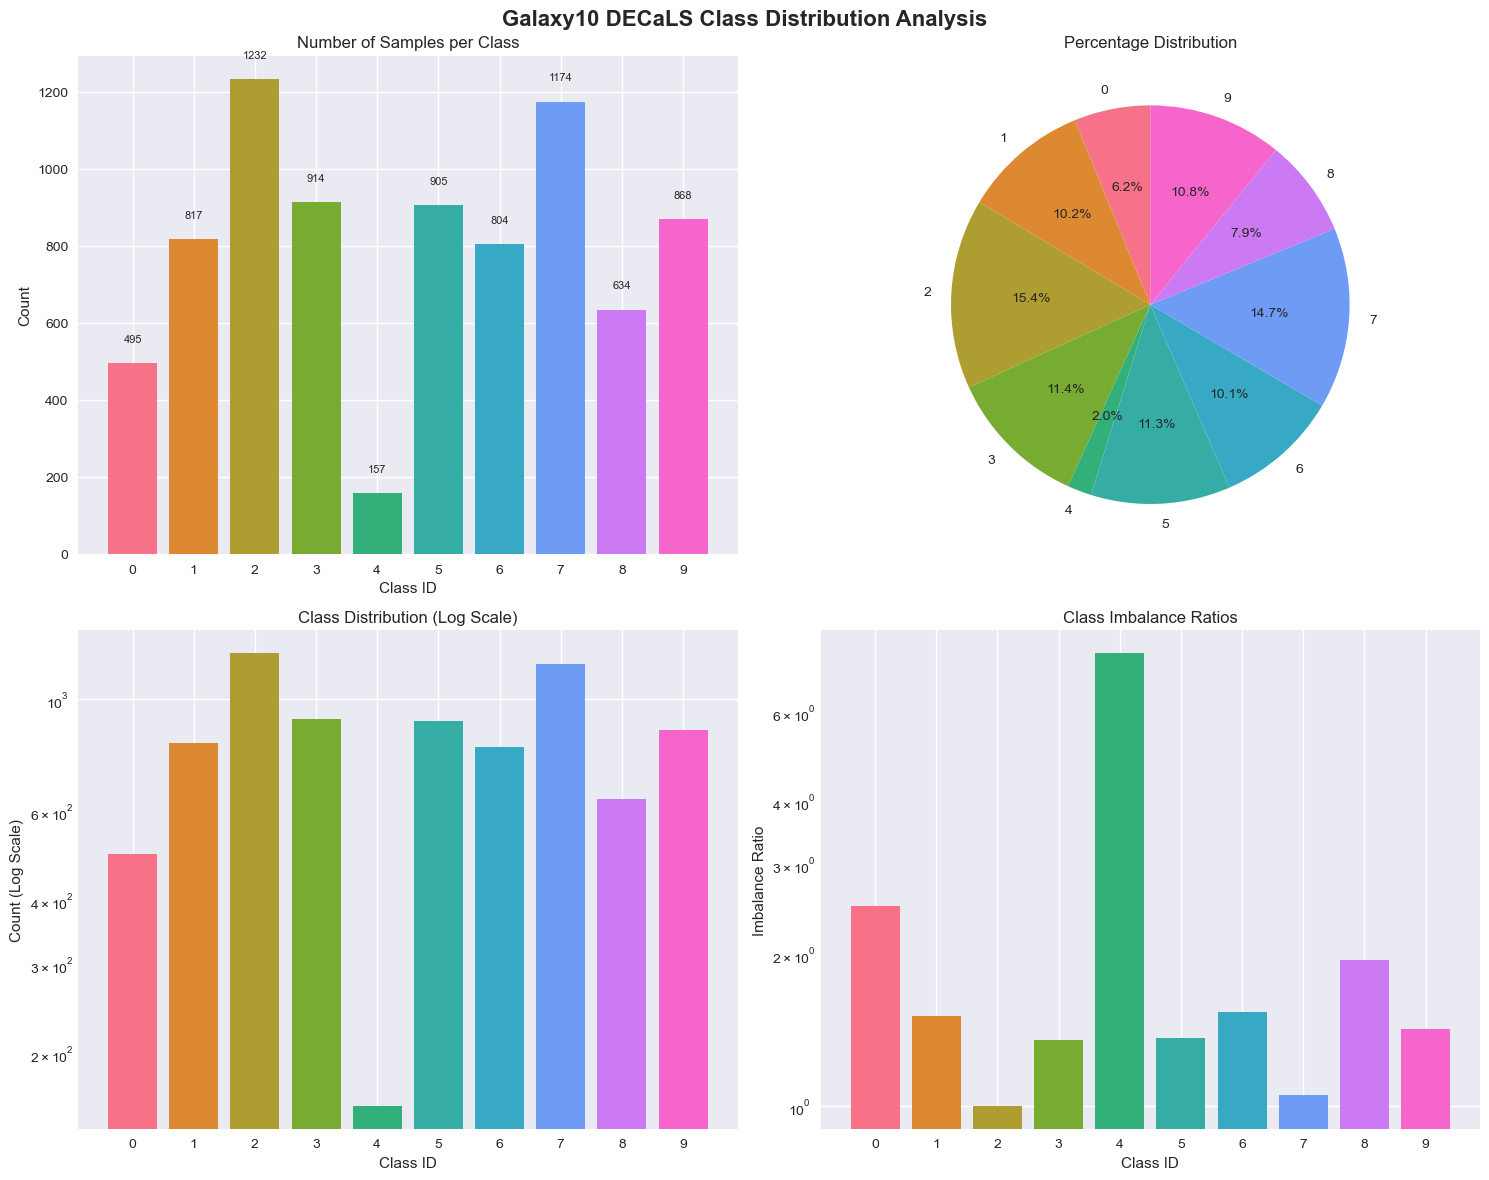

In [4]:
# TO Create comprehensive visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Galaxy10 DECaLS Class Distribution Analysis', fontsize=16, fontweight='bold')

# 1. Bar plot of class counts
ax1 = axes[0, 0]
bars = ax1.bar(df_distribution['Class ID'], df_distribution['Count'], 
              color=sns.color_palette("husl", len(df_distribution)))
ax1.set_title('Number of Samples per Class')
ax1.set_xlabel('Class ID')
ax1.set_ylabel('Count')
ax1.set_xticks(df_distribution['Class ID'])

# Add value labels on bars
for bar, count in zip(bars, df_distribution['Count']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            str(count), ha='center', va='bottom', fontsize=8)

# 2. Pie chart
ax2 = axes[0, 1]
colors = sns.color_palette("husl", len(df_distribution))
wedges, texts, autotexts = ax2.pie(df_distribution['Count'], 
                                  labels=df_distribution['Class ID'],
                                  autopct='%1.1f%%',
                                  colors=colors,
                                  startangle=90)
ax2.set_title('Percentage Distribution')

# 3. Log scale visualization
ax3 = axes[1, 0]
ax3.bar(df_distribution['Class ID'], df_distribution['Count'], 
       color=sns.color_palette("husl", len(df_distribution)))
ax3.set_yscale('log')
ax3.set_title('Class Distribution (Log Scale)')
ax3.set_xlabel('Class ID')
ax3.set_ylabel('Count (Log Scale)')
ax3.set_xticks(df_distribution['Class ID'])

# 4. Imbalance ratio visualization
ax4 = axes[1, 1]
max_count = df_distribution['Count'].max()
imbalance_ratios = max_count / df_distribution['Count']

bars = ax4.bar(df_distribution['Class ID'], imbalance_ratios,
              color=sns.color_palette("husl", len(df_distribution)))
ax4.set_title('Class Imbalance Ratios')
ax4.set_xlabel('Class ID')
ax4.set_ylabel('Imbalance Ratio')
ax4.set_xticks(df_distribution['Class ID'])
ax4.set_yscale('log')

plt.tight_layout()
plt.show()

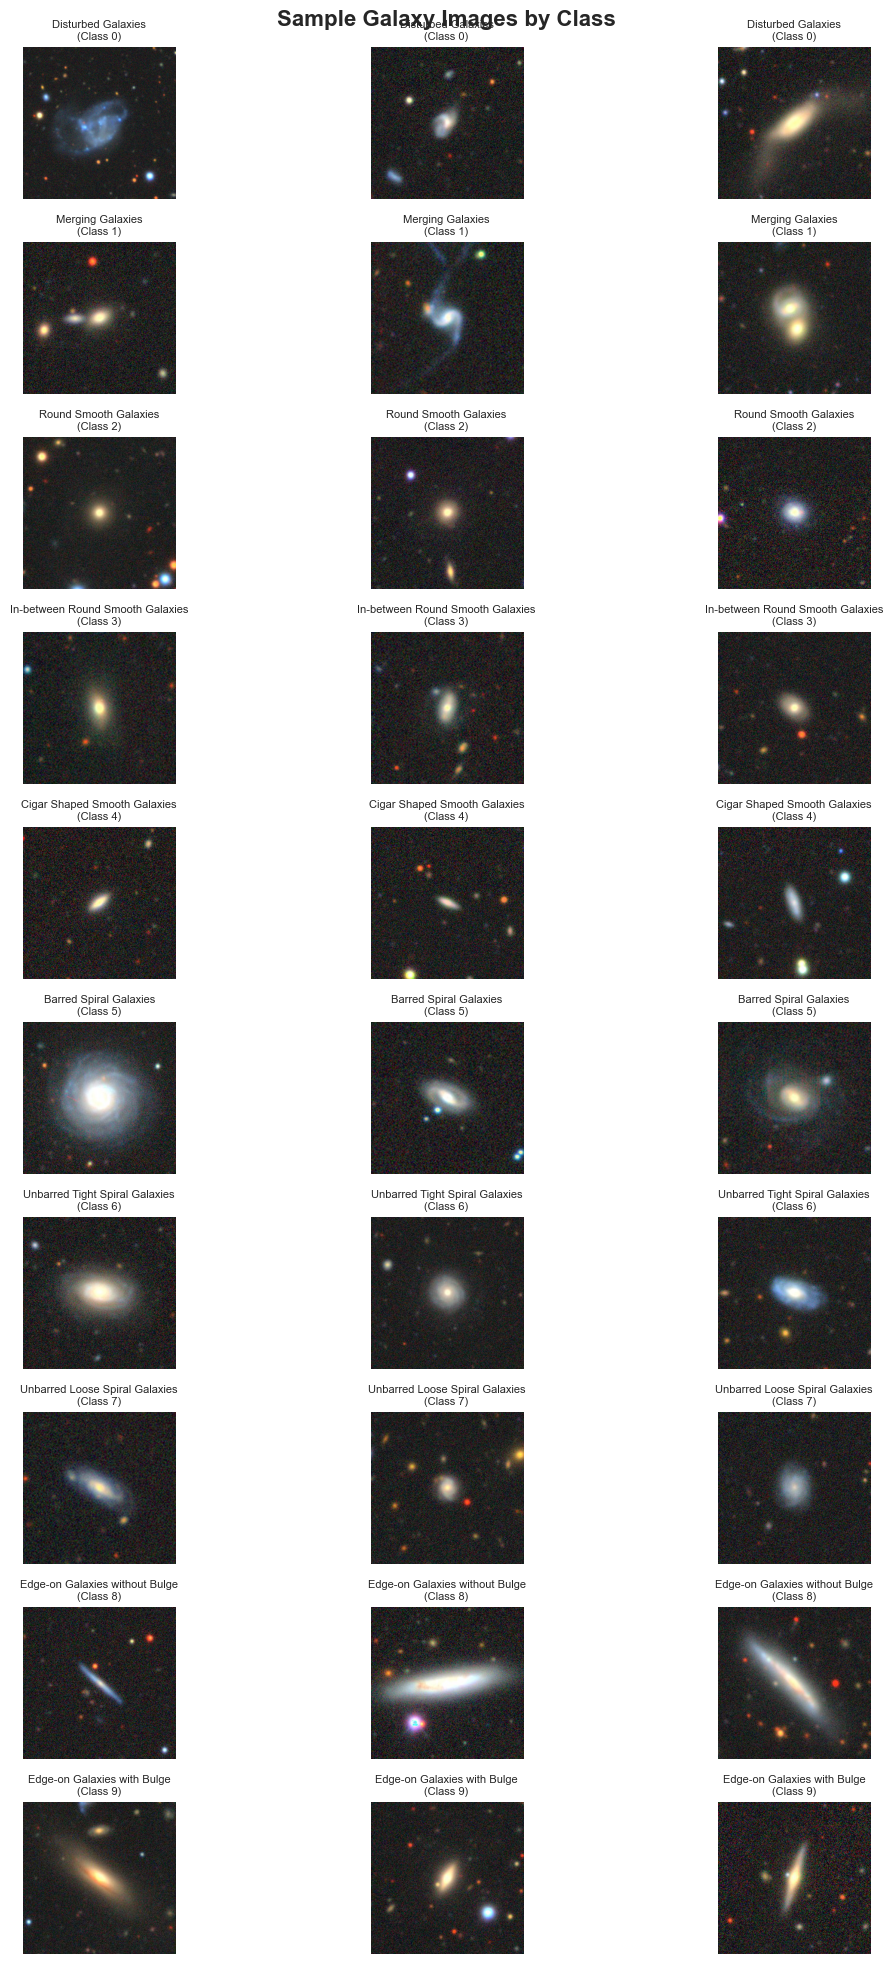

In [5]:
# Visualize sample images from each class
samples_per_class = 3
fig, axes = plt.subplots(len(class_names), samples_per_class, 
                        figsize=(4*samples_per_class, 2*len(class_names)))
fig.suptitle('Sample Galaxy Images by Class', fontsize=16, fontweight='bold')

for class_id in range(len(class_names)):
    class_indices = np.where(labels == class_id)[0]
    
    if len(class_indices) >= samples_per_class:
        sample_indices = np.random.choice(class_indices, samples_per_class, replace=False)
    else:
        sample_indices = np.random.choice(class_indices, samples_per_class, replace=True)
    
    for i, idx in enumerate(sample_indices):
        ax = axes[class_id, i] if len(class_names) > 1 else axes[i]
        
        image = images[idx]
        if image.shape[-1] == 3:
            ax.imshow(image)
        else:
            ax.imshow(image.squeeze(), cmap='gray')
        
        ax.set_title(f'{class_names[class_id]}\n(Class {class_id})', fontsize=8)
        ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:

gc.collect()

# Create stratified train/validation/test splits
print("Creating data splits...")

# First split: 80% train+val, 20% test
X_temp, X_test, y_temp, y_test = train_test_split(
    images, labels, test_size=0.2, stratify=labels, random_state=42
)

# Second split: 75% train, 25% val (of the 80%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42
)

print(f"Data split completed:")
print(f"Train set: {len(X_train)} samples ({len(X_train)/len(images)*100:.1f}%)")
print(f"Validation set: {len(X_val)} samples ({len(X_val)/len(images)*100:.1f}%)")
print(f"Test set: {len(X_test)} samples ({len(X_test)/len(images)*100:.1f}%)")

# Clear original arrays to save memory
del images, labels, X_temp, y_temp
gc.collect()

# Print class distribution in each split
print("\nClass distribution in splits:")
for split_name, split_labels in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    unique, counts = np.unique(split_labels, return_counts=True)
    print(f"{split_name}: {dict(zip(unique, counts))}")

Creating data splits...
Data split completed:
Train set: 4800 samples (60.0%)
Validation set: 1600 samples (20.0%)
Test set: 1600 samples (20.0%)

Class distribution in splits:
Train: {np.uint8(0): np.int64(297), np.uint8(1): np.int64(491), np.uint8(2): np.int64(740), np.uint8(3): np.int64(548), np.uint8(4): np.int64(94), np.uint8(5): np.int64(543), np.uint8(6): np.int64(482), np.uint8(7): np.int64(704), np.uint8(8): np.int64(380), np.uint8(9): np.int64(521)}
Val: {np.uint8(0): np.int64(99), np.uint8(1): np.int64(163), np.uint8(2): np.int64(246), np.uint8(3): np.int64(183), np.uint8(4): np.int64(32), np.uint8(5): np.int64(181), np.uint8(6): np.int64(161), np.uint8(7): np.int64(235), np.uint8(8): np.int64(127), np.uint8(9): np.int64(173)}
Test: {np.uint8(0): np.int64(99), np.uint8(1): np.int64(163), np.uint8(2): np.int64(246), np.uint8(3): np.int64(183), np.uint8(4): np.int64(31), np.uint8(5): np.int64(181), np.uint8(6): np.int64(161), np.uint8(7): np.int64(235), np.uint8(8): np.int64(1

In [ ]:


print("Saving processed data for diffusion model...")

# Create data directory
os.makedirs('data/processed', exist_ok=True)

# Save the train/val/test splits
np.save('data/processed/X_train.npy', X_train)
np.save('data/processed/X_val.npy', X_val) 
np.save('data/processed/X_test.npy', X_test)
np.save('data/processed/y_train.npy', y_train)
np.save('data/processed/y_val.npy', y_val)
np.save('data/processed/y_test.npy', y_test)

# Save metadata
data_info = {
    'train_samples': len(X_train),
    'val_samples': len(X_val),
    'test_samples': len(X_test),
    'image_shape': list(X_train.shape[1:]),  # (H, W, C)
    'num_classes': len(class_names),
    'class_names': class_names,
    'minority_classes': [1, 4, 8, 9],
    'primary_focus_class': 4,
    'subset_size': len(X_train) + len(X_val) + len(X_test),
    'random_seed': 42,
    'split_ratios': {
        'train': 0.6,  # 60% of total
        'val': 0.2,    # 20% of total  
        'test': 0.2    # 20% of total
    }
}

# Save metadata as JSON
with open('data/processed/data_info.json', 'w') as f:
    json.dump(data_info, f, indent=2)

print("Data saved successfully!")
print(f"Train: {X_train.shape} -> data/processed/X_train.npy")
print(f"Val: {X_val.shape} -> data/processed/X_val.npy")
print(f"Test: {X_test.shape} -> data/processed/X_test.npy")
print(f"Metadata: data/processed/data_info.json")
print()
print("Data Saved")

Saving processed data for diffusion model...
Data saved successfully!
Train: (4800, 256, 256, 3) -> data/processed/X_train.npy
Val: (1600, 256, 256, 3) -> data/processed/X_val.npy
Test: (1600, 256, 256, 3) -> data/processed/X_test.npy
Metadata: data/processed/data_info.json

Data Saved


In [ ]:
class BaselineClassifier(nn.Module):
    
    
    def __init__(self, num_classes=10):
        super(BaselineClassifier, self).__init__()
        
        self.densenet = densenet121(pretrained=True)
        self.densenet.classifier = nn.Linear(self.densenet.classifier.in_features, num_classes)
    
    def forward(self, x):
        return self.densenet(x)


if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Initialize model
model = BaselineClassifier().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

print(f"Model initialized on {device}")
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")


C:\Users\ma25751\AppData\Local\anaconda3\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\ma25751\AppData\Local\anaconda3\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Model initialized on cuda
Model parameters: 6,964,106


In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),  
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((128, 128)), 
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create datasets
train_dataset = Galaxy10Dataset(X_train, y_train, transform=train_transform)
val_dataset = Galaxy10Dataset(X_val, y_val, transform=val_test_transform)
test_dataset = Galaxy10Dataset(X_test, y_test, transform=val_test_transform)


batch_size = 8  # Reduced batch size for memory efficiency
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, 
                         num_workers=0, pin_memory=False)  
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, 
                       num_workers=0, pin_memory=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, 
                        num_workers=0, pin_memory=False)


print(f"- Batch size: {batch_size}")
print(f"- Image size: 128x128 ")
print(f"- Workers: 0 ")
print(f"- Train batches: {len(train_loader)}")
print(f"- Validation batches: {len(val_loader)}")
print(f"- Test batches: {len(test_loader)}")


- Batch size: 8
- Image size: 128x128 
- Workers: 0 
- Train batches: 600
- Validation batches: 200
- Test batches: 200


In [ ]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_predictions = 0
    
    for batch_idx, (images, labels) in enumerate(train_loader):
        # Clear cache periodically
        if batch_idx % 100 == 0 and torch.cuda.is_available():
            torch.cuda.empty_cache()
            
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_predictions += labels.size(0)
        correct_predictions += (predicted == labels).sum().item()
        
        
        
        if batch_idx % 200 == 0:
            print(f'  Batch {batch_idx}/{len(train_loader)}, Loss: {loss.item():.4f}')
        
        # Clear variables to free memory
        del images, labels, outputs, loss
    
    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = correct_predictions / total_predictions
    
    return epoch_loss, epoch_accuracy

def validate(model, val_loader, criterion, device):
    
    model.eval()
    running_loss = 0.0
    correct_predictions = 0
    total_predictions = 0
    
    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(val_loader):
            # Clear cache periodically
            if batch_idx % 50 == 0 and torch.cuda.is_available():
                torch.cuda.empty_cache()
                
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_predictions += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()
            
            # Clear variables
            del images, labels, outputs, loss
    
    epoch_loss = running_loss / len(val_loader)
    epoch_accuracy = correct_predictions / total_predictions
    
    return epoch_loss, epoch_accuracy


In [ ]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


num_epochs = 25  
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []
best_val_accuracy = 0.0
best_model_state = None

print(f"\nStarting memory-optimized baseline training for {num_epochs} epochs...")
print("Settings: DenseNet121, 128x128 images, batch_size=8")


start_time = time.time()

for epoch in range(num_epochs):
    print(f'\nEpoch {epoch+1}/{num_epochs}')
    print('-' * 30)
    
    # Clear memory at start of each epoch
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    
    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    
    # Validate
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    
    # Update learning rate
    scheduler.step()
    
    # Store metrics
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    
    print(f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}')
    print(f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')
    
    # Save best model
    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        best_model_state = model.state_dict().copy()
        print(f'New best validation accuracy: {val_acc:.4f}')
    
    # Memory cleanup
    gc.collect()

training_time = time.time() - start_time
print(f'\nTraining completed in {training_time/60:.1f} minutes')
print(f'Best validation accuracy: {best_val_accuracy:.4f}')

# Load best model
model.load_state_dict(best_model_state)



Starting memory-optimized baseline training for 25 epochs...
Settings: DenseNet121, 128x128 images, batch_size=8

Epoch 1/25
------------------------------
  Batch 0/600, Loss: 2.3790
  Batch 200/600, Loss: 2.0373
  Batch 400/600, Loss: 1.6340
Train Loss: 1.7225, Train Acc: 0.3669
Val Loss: 1.5382, Val Acc: 0.4781
New best validation accuracy: 0.4781

Epoch 2/25
------------------------------
  Batch 0/600, Loss: 1.8255
  Batch 200/600, Loss: 1.6488
  Batch 400/600, Loss: 1.0249
Train Loss: 1.4120, Train Acc: 0.4910
Val Loss: 1.2161, Val Acc: 0.5831
New best validation accuracy: 0.5831

Epoch 3/25
------------------------------
  Batch 0/600, Loss: 1.2062
  Batch 200/600, Loss: 0.2946
  Batch 400/600, Loss: 1.2804
Train Loss: 1.2363, Train Acc: 0.5631
Val Loss: 1.3064, Val Acc: 0.5656

Epoch 4/25
------------------------------
  Batch 0/600, Loss: 1.0101
  Batch 200/600, Loss: 1.1188
  Batch 400/600, Loss: 1.6602
Train Loss: 1.1333, Train Acc: 0.6119
Val Loss: 1.3735, Val Acc: 0.5719


<All keys matched successfully>

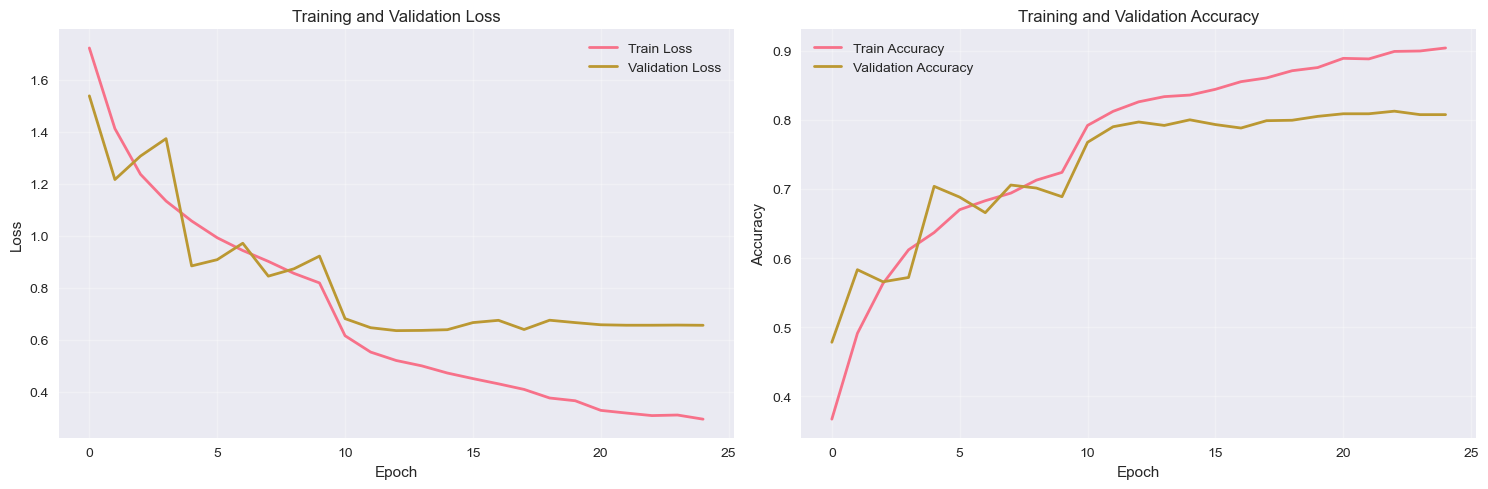

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Loss plot
ax1.plot(train_losses, label='Train Loss', linewidth=2)
ax1.plot(val_losses, label='Validation Loss', linewidth=2)
ax1.set_title('Training and Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Accuracy plot
ax2.plot(train_accuracies, label='Train Accuracy', linewidth=2)
ax2.plot(val_accuracies, label='Validation Accuracy', linewidth=2)
ax2.set_title('Training and Validation Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

print("DETAILED BASELINE PERFORMANCE EVALUATION")



gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

model.eval()
all_predictions = []
all_labels = []

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(test_loader):
       
        if batch_idx % 50 == 0 and torch.cuda.is_available():
            torch.cuda.empty_cache()
            
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        
        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        
       
        del images, labels, outputs

# Convert to numpy arrays
y_true = np.array(all_labels)
y_pred = np.array(all_predictions)

# Overall accuracy
overall_accuracy = np.mean(y_true == y_pred)
print(f"Overall Test Accuracy: {overall_accuracy:.4f}")


print("\nPer class Performance:")
print("-" * 40)

class_report = classification_report(
    y_true, y_pred, 
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Focus on minority classes performance
minority_classes_ids = [1, 4, 8, 9]  # Based on typical Galaxy10 distribution
print("\nMINORITY CLASS PERFORMANCE")


minority_f1_scores = []
for class_id in minority_classes_ids:
    if class_id < len(class_names):
        class_name = class_names[class_id]
        precision = class_report[class_name]['precision']
        recall = class_report[class_name]['recall'] 
        f1 = class_report[class_name]['f1-score']
        support = class_report[class_name]['support']
        
        minority_f1_scores.append(f1)
        print(f"Class {class_id} ({class_name}):")
        print(f"  Precision: {precision:.3f}")
        print(f"  Recall: {recall:.3f}")
        print(f"  F1-score: {f1:.3f}")
        print(f"  Support: {int(support)}")
        print()

# Average F1 for minority classes
avg_minority_f1 = np.mean(minority_f1_scores)
print(f"Average F1-score for minority classes: {avg_minority_f1:.3f}")


cigar_class_name = class_names[4]
cigar_f1 = class_report[cigar_class_name]['f1-score']
print(f"\nPRIMARY FOCUS CLASS - {cigar_class_name}:")
print(f"Baseline F1-score: {cigar_f1:.3f}")


# Full classification report
print(f"\nFull Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))


DETAILED BASELINE PERFORMANCE EVALUATION
Overall Test Accuracy: 0.8094

Per class Performance:
----------------------------------------

MINORITY CLASS PERFORMANCE
Class 1 (Merging Galaxies):
  Precision: 0.849
  Recall: 0.791
  F1-score: 0.819
  Support: 163

Class 4 (Cigar Shaped Smooth Galaxies):
  Precision: 0.619
  Recall: 0.839
  F1-score: 0.712
  Support: 31

Class 8 (Edge-on Galaxies without Bulge):
  Precision: 0.848
  Recall: 0.921
  F1-score: 0.883
  Support: 127

Class 9 (Edge-on Galaxies with Bulge):
  Precision: 0.899
  Recall: 0.925
  F1-score: 0.912
  Support: 174

Average F1-score for minority classes: 0.832

PRIMARY FOCUS CLASS - Cigar Shaped Smooth Galaxies:
Baseline F1-score: 0.712

Full Classification Report:
                                  precision    recall  f1-score   support

              Disturbed Galaxies       0.51      0.31      0.39        99
                Merging Galaxies       0.85      0.79      0.82       163
           Round Smooth Galaxies     

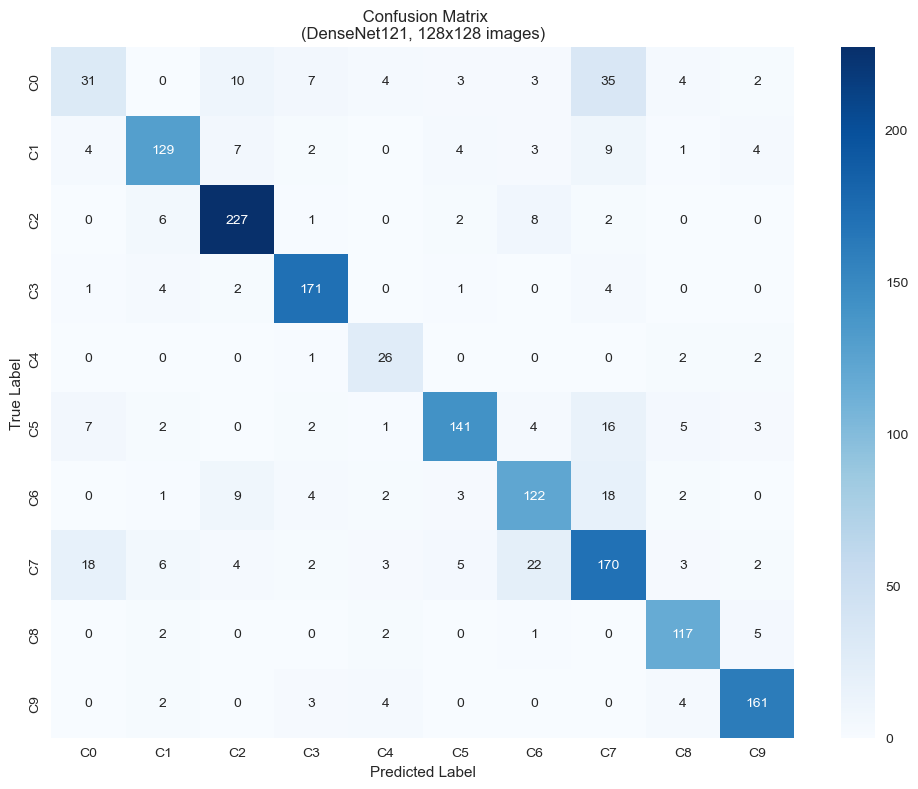

Key baseline metrics established:
- Model: DenseNet121 
- Image size: 128x128
- Overall accuracy: 0.809
- Average minority class F1: 0.832
- Cigar Shaped Galaxies F1: 0.712
- Training time: 23.0 minutes

Baseline results saved to results/baseline/


In [14]:
# Plot confusion matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=[f'C{i}' for i in range(len(class_names))],
           yticklabels=[f'C{i}' for i in range(len(class_names))])
plt.title(' Confusion Matrix\n(DenseNet121, 128x128 images)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

# Save baseline results
os.makedirs('results/baseline', exist_ok=True)

baseline_results = {
    'model_config': {
        'architecture': 'DenseNet121',
        'image_size': '128x128',
        'batch_size': batch_size,
        'epochs': num_epochs,
        'optimizer': 'Adam',
        'learning_rate': 0.001
    },
    'performance': {
        'overall_accuracy': float(overall_accuracy),
        'avg_minority_f1': float(avg_minority_f1),
        'cigar_class_f1': float(cigar_f1),
        'best_val_accuracy': float(best_val_accuracy)
    },
    'class_report': class_report,
    'training_history': {
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_accuracies': train_accuracies,
        'val_accuracies': val_accuracies
    },
    'training_time_minutes': training_time / 60,
    'timestamp': datetime.now().isoformat()
}

# Save metrics
with open('results/baseline/baseline_metrics.json', 'w') as f:
    json.dump(baseline_results, f, indent=2)

# Save model
torch.save(model.state_dict(), 'results/baseline/baseline_model.pth')


print("Key baseline metrics established:")
print(f"- Model: DenseNet121 ")
print(f"- Image size: 128x128")
print(f"- Overall accuracy: {overall_accuracy:.3f}")
print(f"- Average minority class F1: {avg_minority_f1:.3f}")
print(f"- Cigar Shaped Galaxies F1: {cigar_f1:.3f}")
print(f"- Training time: {training_time/60:.1f} minutes")
print("\nBaseline results saved to results/baseline/")



In [15]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()



# Store baseline metrics for comparison
BASELINE_METRICS = {
    'overall_accuracy': overall_accuracy,
    'avg_minority_f1': avg_minority_f1,
    'cigar_class_f1': cigar_f1,
    'minority_classes': minority_classes_ids,
    'model_config': {
        'architecture': 'DenseNet121',
        'image_size': (128, 128),
        'batch_size': batch_size
    }
}

In [ ]:


print("Saving processed data for diffusion model...")

# Create data directory
os.makedirs('data/processed', exist_ok=True)

# Save the train/val/test splits
np.save('data/processed/X_train.npy', X_train)
np.save('data/processed/X_val.npy', X_val) 
np.save('data/processed/X_test.npy', X_test)
np.save('data/processed/y_train.npy', y_train)
np.save('data/processed/y_val.npy', y_val)
np.save('data/processed/y_test.npy', y_test)

# Save metadata
data_info = {
    'train_samples': len(X_train),
    'val_samples': len(X_val),
    'test_samples': len(X_test),
    'image_shape': list(X_train.shape[1:]),  # (H, W, C)
    'num_classes': len(class_names),
    'class_names': class_names,
    'minority_classes': [1, 4, 8, 9],
    'primary_focus_class': 4,
    'subset_size': len(X_train) + len(X_val) + len(X_test),
    'random_seed': 42,
    'split_ratios': {
        'train': 0.6,  # 60% of total
        'val': 0.2,    # 20% of total  
        'test': 0.2    # 20% of total
    }
}


with open('data/processed/data_info.json', 'w') as f:
    json.dump(data_info, f, indent=2)

print("Data saved successfully!")
print(f"Train: {X_train.shape} -> data/processed/X_train.npy")
print(f"Val: {X_val.shape} -> data/processed/X_val.npy")
print(f"Test: {X_test.shape} -> data/processed/X_test.npy")
print(f"Metadata: data/processed/data_info.json")
print()


Saving processed data for diffusion model...
Data saved successfully!
Train: (4800, 256, 256, 3) -> data/processed/X_train.npy
Val: (1600, 256, 256, 3) -> data/processed/X_val.npy
Test: (1600, 256, 256, 3) -> data/processed/X_test.npy
Metadata: data/processed/data_info.json

